# ItemKNN: sensibilidad, selección y evaluación reproducible

Se conserva este notebook como punto de entrada del método. El experimento usa todas las interacciones de entrenamiento y validación y exporta sus tablas, figuras y protocolo a `tarea_01/informe_assets`.

Comparamos Pearson y MSD para k = 10, 30, 50 y 80. El número k es un máximo: solo cuentan vecinos con similitud positiva. Medimos la fracción de predicciones sin vecinos suficientes para contrastar esta explicación de la meseta.

La selección de hiperparámetros usa validación: los resultados son exploratorios, sin test independiente. Semilla 42 es una decisión del experimento.

In [1]:
import sys
from pathlib import Path

project_root = next(
    p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (p / "tarea_01" / "utils.py").exists()
)
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

import pandas as pd
from IPython.display import Image, display

from tarea_01.experiments_item_funksvd import run_family
from tarea_01.plot_item_funksvd_results import (
    plot_family_ranking,
    plot_family_sensitivity,
    save_item_diagnostics,
)

output_dir = project_root / "tarea_01" / "informe_assets" / "data"
figure_dir = output_dir.parent
SEED = 42
NEGATIVES = 100
K = 10
THRESHOLD = 4.0

## Entrenamiento y grilla completa

Se ejecuta la misma implementación que usa el comando reproducible del README. Los CSV conservan precisión completa; el redondeo solo afecta la presentación. Cada configuración se evalúa en rating y ranking con los mismos candidatos.

In [2]:
experiment = run_family(
    "ItemKNN",
    output_dir=output_dir,
    random_state=SEED,
    ranking_negatives=NEGATIVES,
    top_k=K,
    relevance_threshold=THRESHOLD,
)
sensitivity = experiment["sensitivity"]
config_columns = ["k_neighbors", "similarity", "min_k"]
sensitivity[config_columns + ["RMSE", "MAE", "Recall@10", "NDCG@10", "MAP@10"]].round(6)

item_pearson_k10_min1: RMSE=0.997408, MAE=0.538797


item_pearson_k30_min1: RMSE=0.996893, MAE=0.538975


item_pearson_k50_min1: RMSE=0.996906, MAE=0.539042


item_pearson_k80_min1: RMSE=0.996900, MAE=0.539029


item_msd_k10_min1: RMSE=0.926919, MAE=0.489133


item_msd_k30_min1: RMSE=0.913144, MAE=0.484821


item_msd_k50_min1: RMSE=0.911496, MAE=0.485011


item_msd_k80_min1: RMSE=0.910791, MAE=0.485202


,k_neighbors,similarity,min_k,RMSE,MAE,Recall@10,NDCG@10,MAP@10
0,10,pearson,1,0.997408,0.538797,0.160531,0.123601,0.063317
1,30,pearson,1,0.996893,0.538975,0.160347,0.123531,0.063475
2,50,pearson,1,0.996906,0.539042,0.160328,0.123436,0.063359
3,80,pearson,1,0.996900,0.539029,0.160328,0.123436,0.063359
4,10,msd,1,0.926919,0.489133,0.083136,0.069547,0.034160
5,30,msd,1,0.913144,0.484821,0.072931,0.059688,0.029342
6,50,msd,1,0.911496,0.485011,0.072200,0.059262,0.029166
7,80,msd,1,0.910791,0.485202,0.071254,0.057394,0.028215


## Sensibilidad y elección del objetivo

Las curvas muestran qué cambia al aumentar capacidad, manteniendo identificables los demás hiperparámetros. Los ejes de error y ranking usan zoom; hay que interpretar los cambios absolutos indicados, no solo la pendiente visual. El diagnóstico de vecinos efectivos contrasta el k solicitado con la señal realmente disponible y con el uso de fallback.

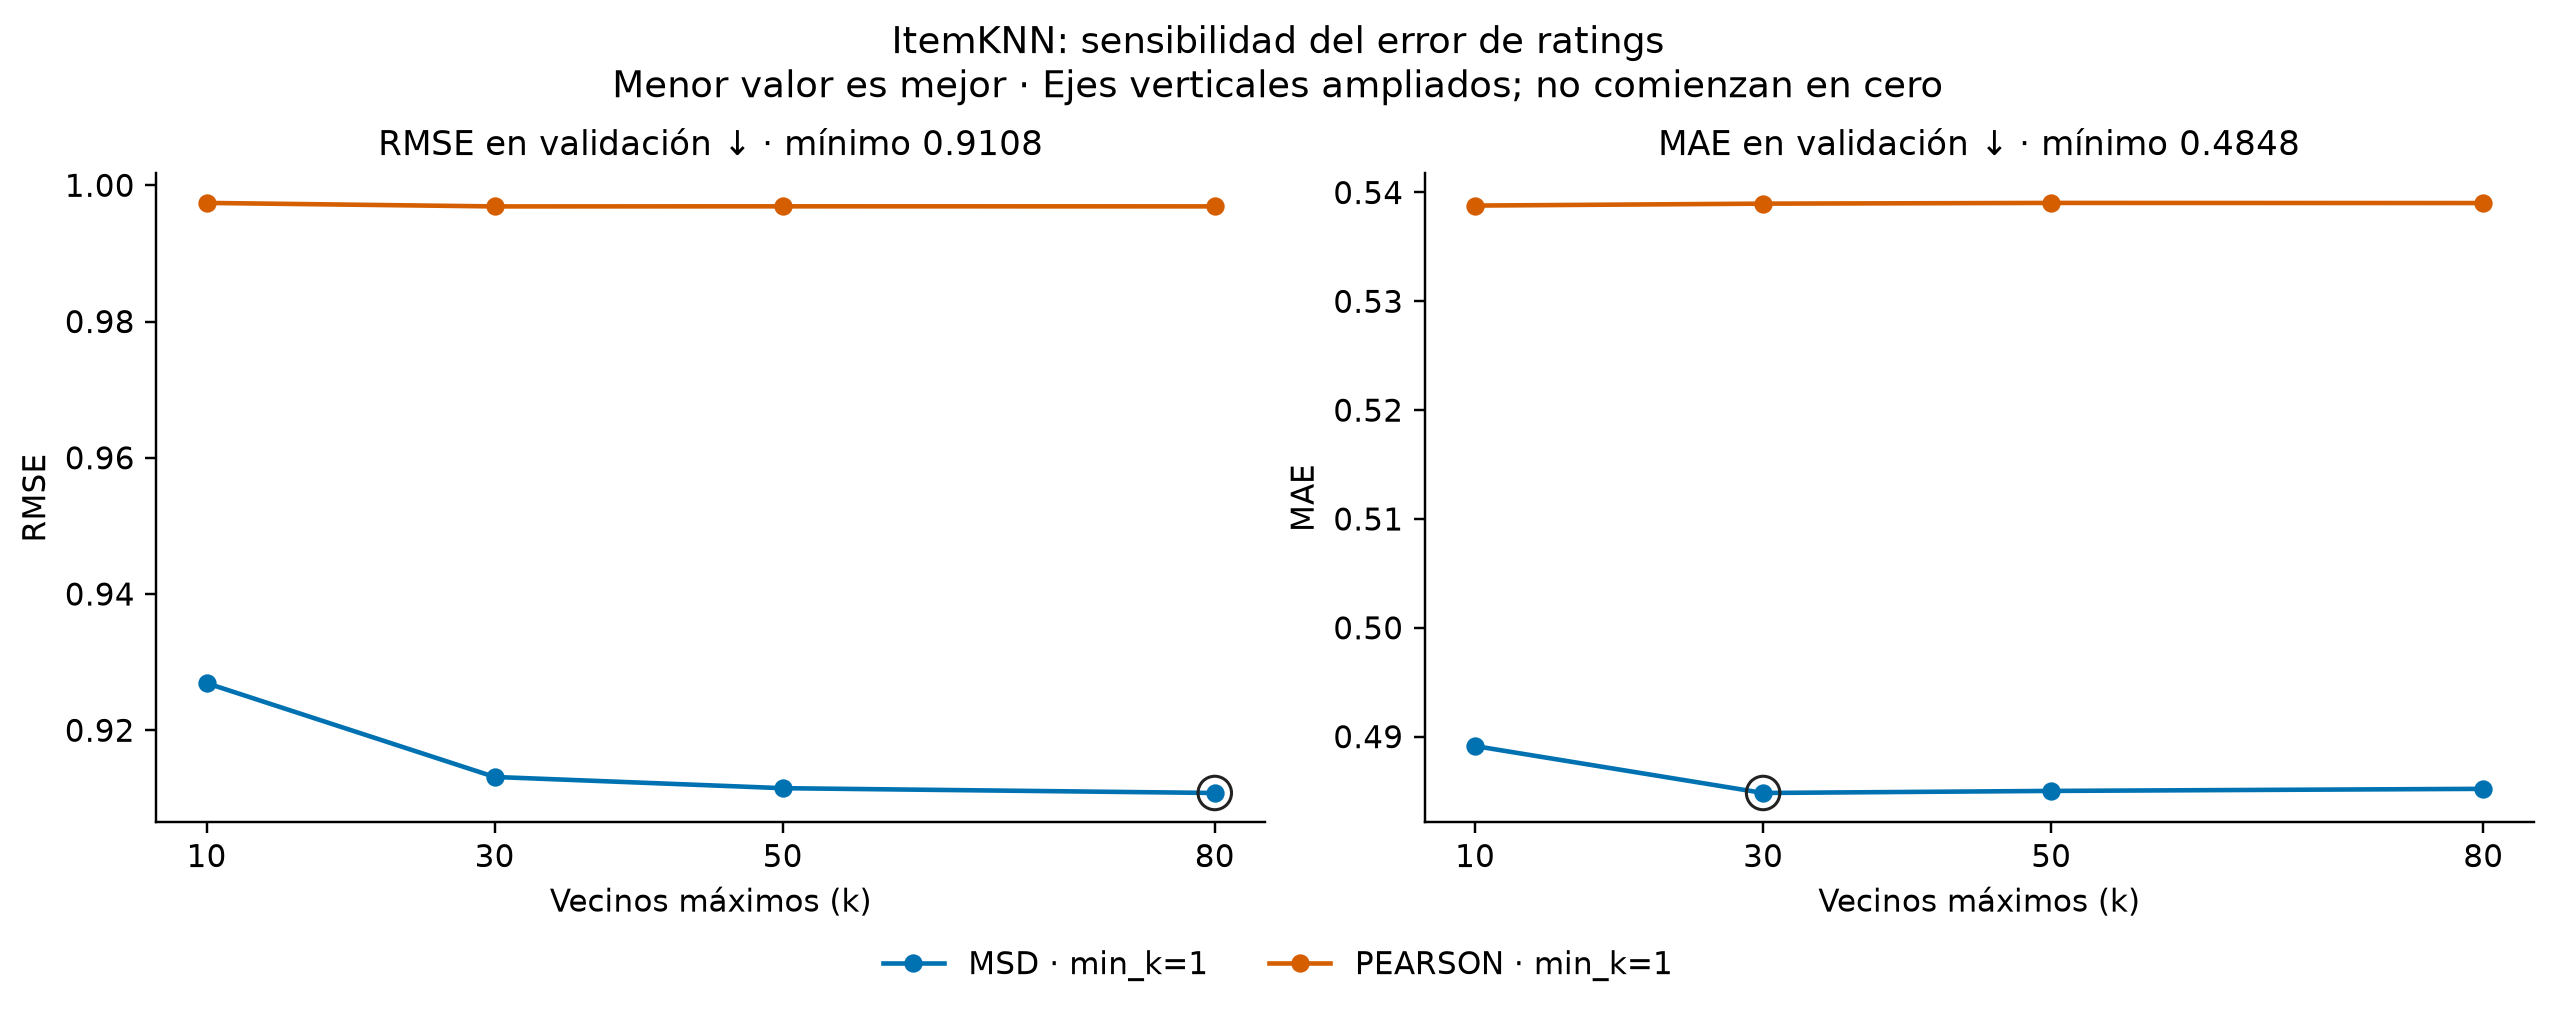

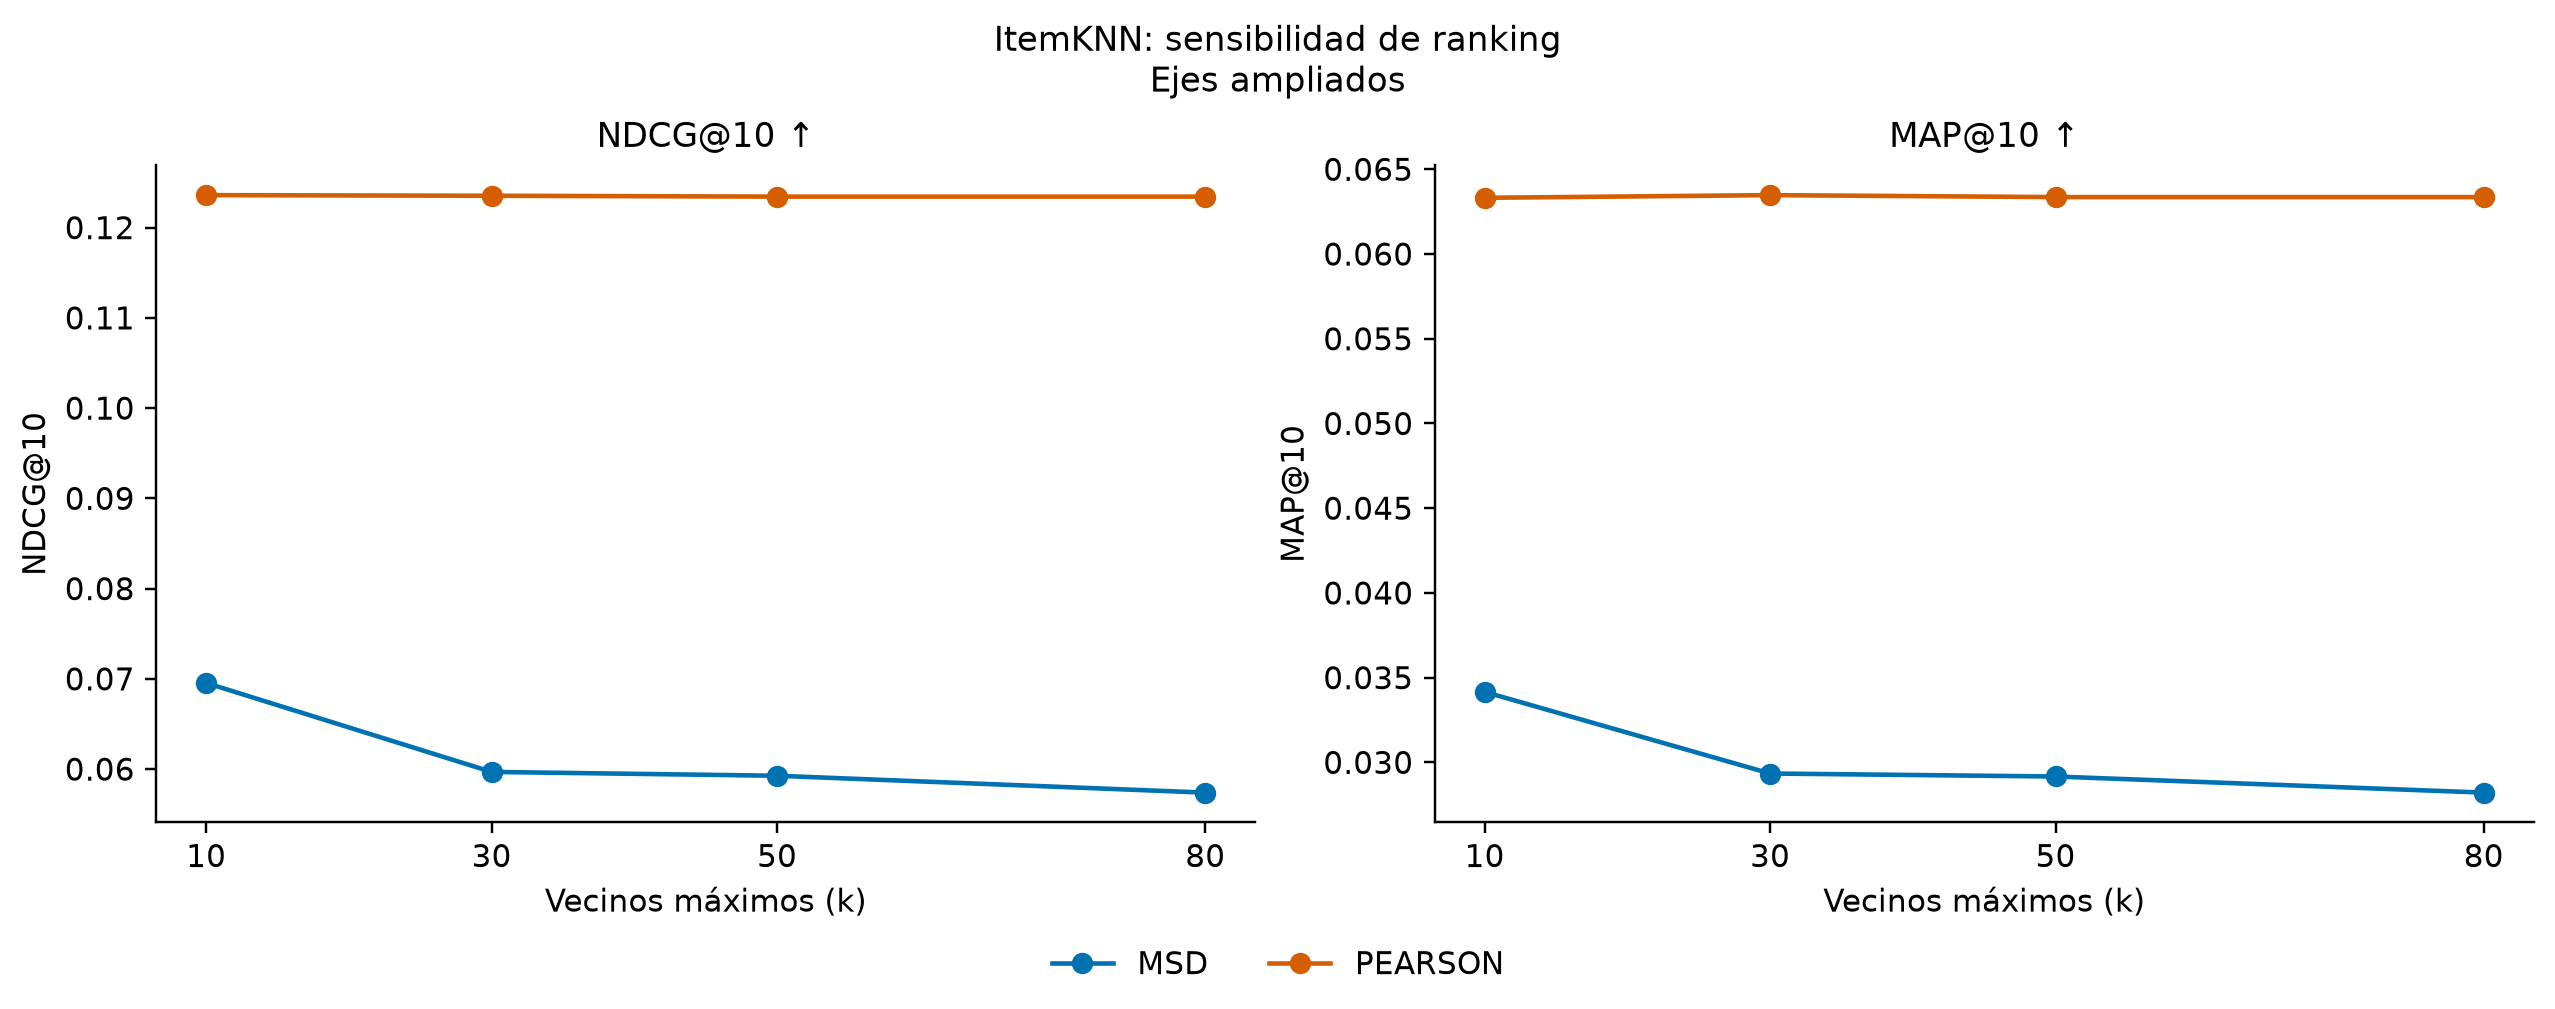

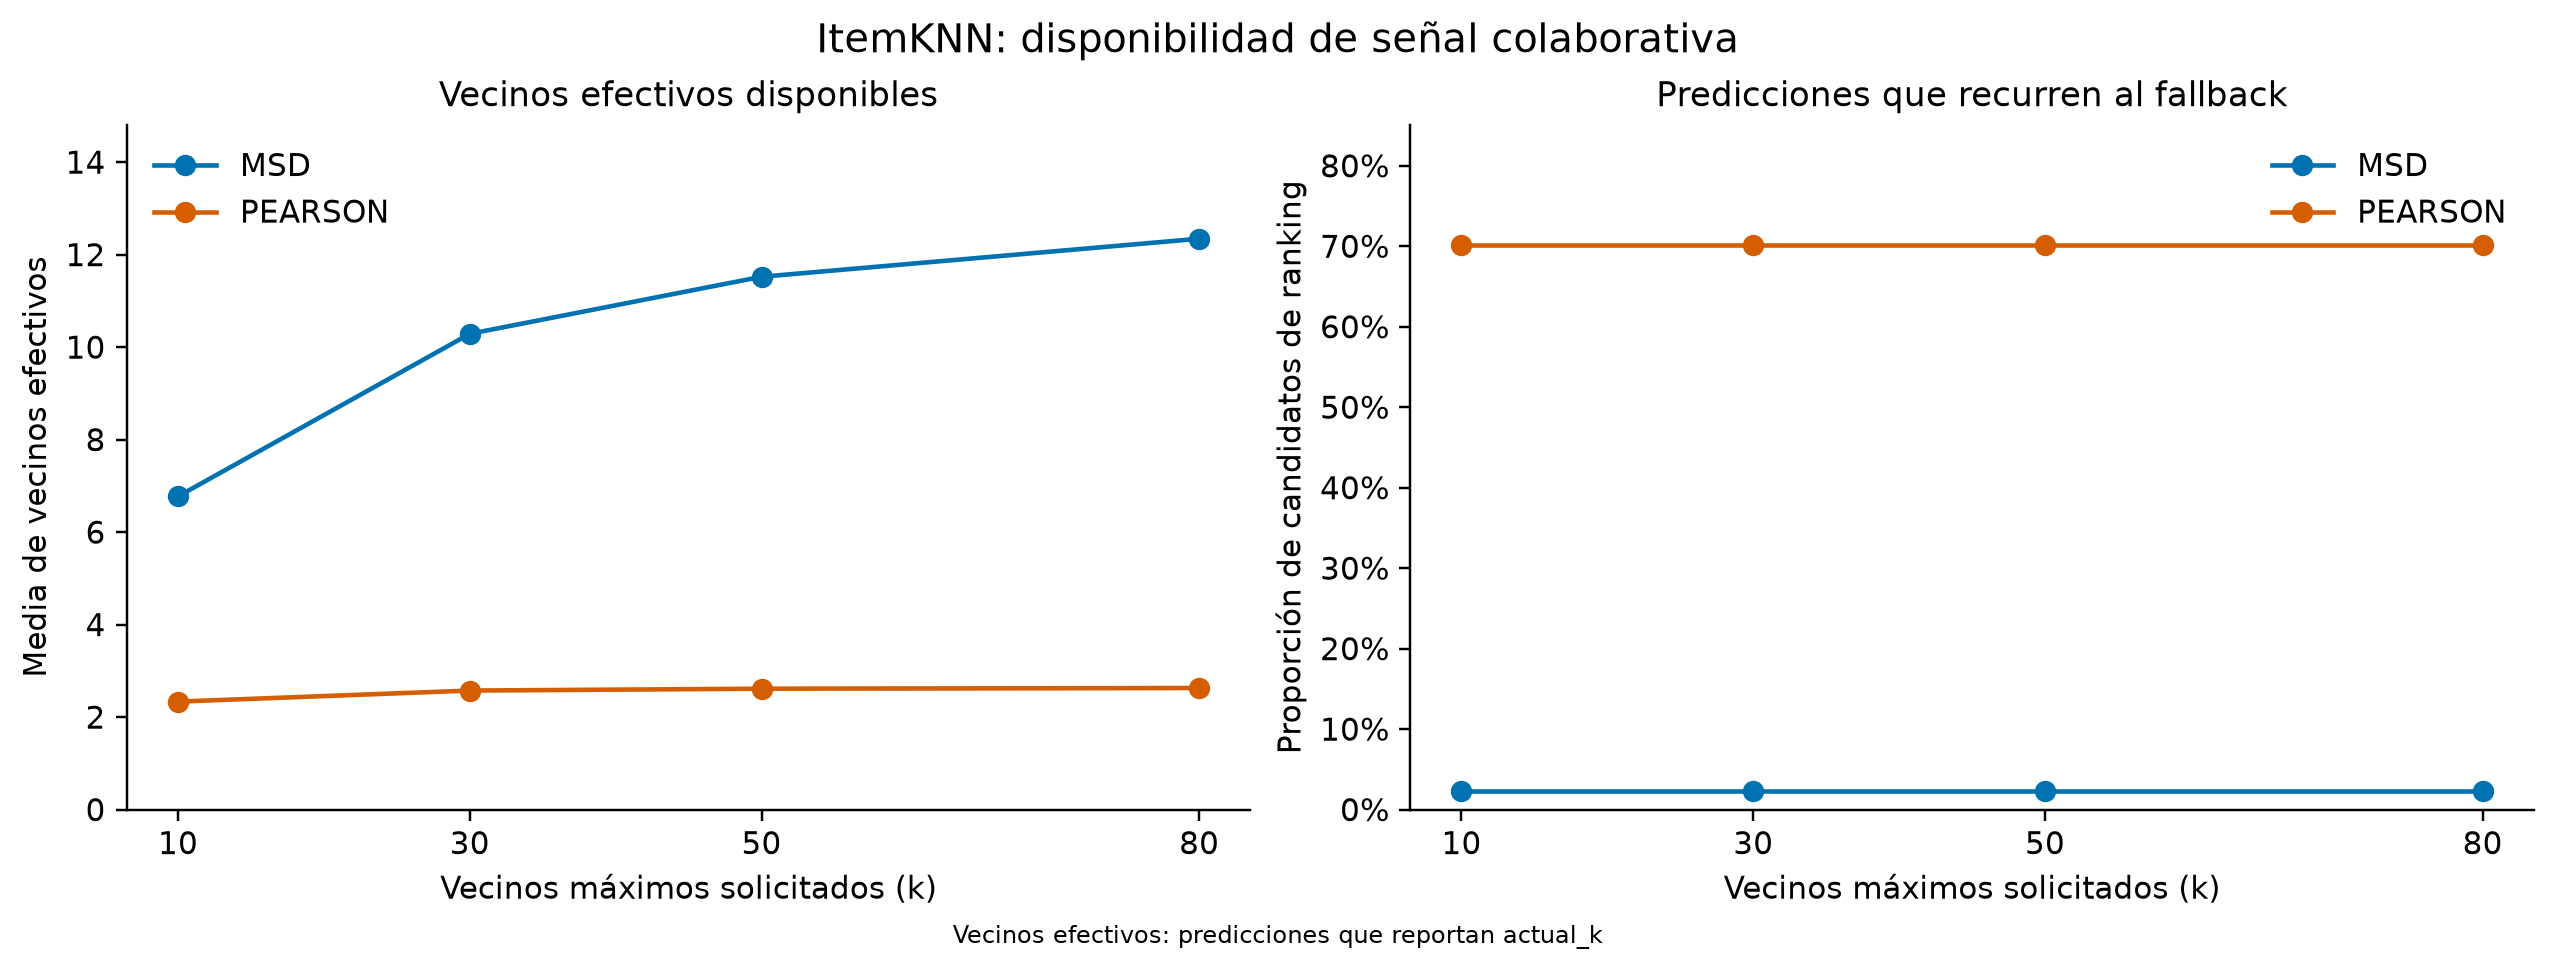

In [3]:
figure_path = plot_family_sensitivity(sensitivity, "ItemKNN", figure_dir)
display(Image(filename=figure_path))
ranking_path = plot_family_ranking(sensitivity, "ItemKNN", figure_dir)
display(Image(filename=ranking_path))
diagnostic_path = figure_dir / "itemknn_neighbors.png"
save_item_diagnostics(sensitivity, diagnostic_path)
display(Image(filename=diagnostic_path))

In [4]:
objectives = {"RMSE": "min", "MAE": "min", "NDCG@10": "max"}
choices = []
for metric, direction in objectives.items():
    index = sensitivity[metric].idxmin() if direction == "min" else sensitivity[metric].idxmax()
    row = sensitivity.loc[index]
    choices.append({"Objetivo": metric, **row[config_columns + ["RMSE", "MAE", "NDCG@10"]].to_dict()})
pd.DataFrame(choices).round(6)

,Objetivo,k_neighbors,similarity,min_k,RMSE,MAE,NDCG@10
0,RMSE,80,msd,1,0.910791,0.485202,0.057394
1,MAE,30,msd,1,0.913144,0.484821,0.059688
2,NDCG@10,10,pearson,1,0.997408,0.538797,0.123601


## Top-10 y métricas de descubrimiento

Se incluyen **todas las interacciones de validación**, incluso ratings menores que 4, y 100 recetas no vistas por usuario. Se excluyen las recetas vistas en entrenamiento. Los scores de ranking no se recortan; en empates se usa recipe_id ascendente, sin consultar la relevancia. RMSE y MAE usan únicamente ratings reales, recortados a [0,5].

`TagDiversity` cuenta tags distintos por lista; se informa como aproximación operativa a variedad de contenido, sin afirmar que cada tag es un estilo culinario. `InteractionILD` mide disimilitud colaborativa. La novedad se muestra en bits por ítem y por lista. Esta evaluación muestreada no equivale a usar todo el catálogo.

In [5]:
evaluation = experiment["evaluation"]
pd.DataFrame([evaluation.metrics], index=["ItemKNN: elegido por RMSE"]).T

,ItemKNN: elegido por RMSE
RMSE,0.910791
MAE,0.485202
Precision@10,0.035709
Recall@10,0.071254
NDCG@10,0.057394
MAP@10,0.028215
InteractionILD,0.986857
TagDiversity,91.468785
TagMetadataCoverage,1.000000
NoveltyBitsPerList,132.854241


## Evidencia de la selección

Los siguientes registros permiten inspeccionar usuarios concretos y corroborar el ranking; los archivos exportados incluyen el conjunto de candidatos identificado por hash. Los hallazgos del informe deben referirse a este protocolo y a estas configuraciones.

In [6]:
display(evaluation.per_user.head())
display(evaluation.top_k.head(10))
evaluation.protocol

,user_id,Candidates,RelevantItems,HasRelevant,RecommendedItems,Hits,Precision@10,Recall@10,NDCG@10,MAP@10,...,TagMetadataCoverage,NoveltyBitsPerItem,NoveltyBitsPerList,NoveltyKnownItemFraction,RankingFallbackFraction,RankingTiedCandidateFraction,RankingTieAt10,ActualKMean,ActualKMin,TrainInteractions
0,1533,104,4,True,10,0,0.0,0.000000,0.000000,0.000000,...,1.0,13.351357,133.513571,1.0,0.096154,0.826923,True,3.021277,1,11
1,1535,114,13,True,10,3,0.3,0.230769,0.275847,0.108571,...,1.0,13.177126,131.771255,1.0,0.000000,0.000000,False,51.719298,7,202
2,1891,102,2,True,10,0,0.0,0.000000,0.000000,0.000000,...,1.0,13.582279,135.822785,1.0,0.000000,0.460784,False,5.274510,1,16
3,2310,109,9,True,10,0,0.0,0.000000,0.000000,0.000000,...,1.0,13.491376,134.913759,1.0,0.000000,0.238532,True,15.339450,2,53
4,2312,105,5,True,10,0,0.0,0.000000,0.000000,0.000000,...,1.0,13.005142,130.051416,1.0,0.009524,0.561905,True,7.711538,1,28


,user_id,recipe_id,true_rating,is_validation,is_relevant,score,raw_score,rating_est,was_impossible,actual_k,outside_rating_scale,rank,train_count,self_information_bits,metadata_tags_known
0,1533,50353,0.0,False,False,5.0,5.0,5.0,False,5.0,True,1,16,13.261397,True
1,1533,12429,0.0,False,False,5.0,5.0,5.0,False,2.0,False,2,10,13.939469,True
2,1533,16810,0.0,False,False,5.0,5.0,5.0,False,4.0,False,3,12,13.676435,True
3,1533,17598,0.0,False,False,5.0,5.0,5.0,False,5.0,False,4,27,12.506510,True
4,1533,17963,0.0,False,False,5.0,5.0,5.0,False,2.0,False,5,11,13.801966,True
5,1533,18556,0.0,False,False,5.0,5.0,5.0,False,3.0,False,6,18,13.091472,True
6,1533,19042,0.0,False,False,5.0,5.0,5.0,False,5.0,False,7,29,12.403416,True
7,1533,23481,0.0,False,False,5.0,5.0,5.0,False,2.0,False,8,12,13.676435,True
8,1533,24907,0.0,False,False,5.0,5.0,5.0,False,3.0,False,9,15,13.354507,True
9,1533,26333,0.0,False,False,5.0,5.0,5.0,False,2.0,False,10,11,13.801966,True


{'protocol_version': 'validation-unseen-v2-raw-score-item-id-ties',
 'ranking_candidate_mode': 'negative_sample_100',
 'k': 10,
 'relevance_threshold': 4.0,
 'n_negatives': 100,
 'seed': 42,
 'sampler': 'numpy.default_rng; sorted users and catalog; without replacement',
 'tie_break': 'score descending, raw item ID ascending',
 'validation_items': 'all observed validation items, including ratings below threshold',
 'unobserved_relevance': 'unknown, treated as zero for offline ranking',
 'accuracy_population': 'macro mean over users with at least one relevant validation item',
 'beyond_accuracy_population': 'all evaluated users',
 'precision_denominator': 10,
 'map_denominator': 'min(k, number of relevant validation items)',
 'novelty_probability': 'training item observation count / training observation count',
 'interaction_ild': 'mean pairwise 1-cosine of binary training item-user vectors',
 'tag_diversity': 'mean distinct raw metadata tags in each recommendation list',
 'unknown_metad

## Fuentes y límites

[KNNBasic y vecinos efectivos, documentación oficial](https://surprise.readthedocs.io/en/stable/knn_inspired.html). [Métricas con candidatos muestreados](https://arxiv.org/abs/1912.02263).

La grilla no prueba que el método ganador lo sea en todo escenario; la semilla fija permite repetir la corrida, pero no reemplaza un análisis de variabilidad. El consolidado usa la configuración elegida por RMSE y distingue este criterio de una selección por nDCG.